# Enrutar entre modelos: costo, calidad y garantías (cascadas, enrutadores, caché y control conforme del riesgo)

**Perfil:** IA y automatización  
**Datos:** simulación con verdad conocida (sin LLM reales ni red): probabilidades de acierto por nivel, costos y latencias configurables; semilla fija.

## Pregunta que guía el notebook

Un sistema que puede llamar a un modelo pequeño (barato, rápido, menos preciso) o a uno grande (30 veces más caro) tiene que decidir **a quién preguntar**. Las respuestas habituales ("si el modelo pequeño está seguro, quédate con él") dependen de que su *confianza* esté bien calibrada. ¿Cuánto se ahorra a igual calidad? ¿Qué pasa si el modelo es sobreconfiado? ¿Se puede **garantizar** una pérdida de calidad máxima? ¿Cuándo conviene un enrutador aprendido, un caché semántico o un bandido en línea?

## Recorrido

1. **Un mundo simulado** con tres niveles (costo 1 : 6 : 30), dificultad latente, resultados correlacionados y una señal de confianza calibrada o sobreconfiada.
2. **Cota de oráculo** y siempre-un-nivel como referencias.
3. **Cascada por confianza:** frontera de Pareto y el efecto de la calibración.
4. **Enrutador aprendido** desde atributos de la consulta, frente a la cascada.
5. **Control conforme del riesgo:** umbral con garantía de muestra finita para la pérdida de calidad, validado por simulación; contraste con el umbral ingenuo.
6. **Caché semántico:** aciertos frente a respuestas equivocadas según el umbral de similitud.
7. **Bandidos en línea:** arrepentimiento de ε-greedy, UCB y Thompson, y el costo de no explorar.
8. **Asignación bajo presupuesto** con relajación de Lagrange y cota de programación lineal.
9. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import sys, itertools
sys.path.insert(0, "src")
from routerlab.world import World, DEFAULT_TIERS, sigmoid, logit
from routerlab import policies as PO, conformal as CF, bandits as BA, optimize as OP
from routerlab.cache import simulate_cache

## 2. El mundo y las referencias

Tres niveles: **small** (costo 1, 200 ms, habilidad −0,3), **medium** (6, 700 ms, 0,6), **large** (30, 2.200 ms, 1,6). La consulta tiene una dificultad latente $d\sim N(0,1)$ y cada nivel acierta con probabilidad $\sigma(1{,}5\,(\text{habilidad}-d))$. Los resultados de los niveles comparten un factor latente (correlación entre niveles) y se sortean **una sola vez** por consulta, de modo que todas las políticas se comparan sobre las mismas realizaciones. Cada nivel emite una **confianza** (calibrada: $p$ más ruido; sobreconfiada: logit multiplicado por 2). El **oráculo** conoce los resultados y elige el nivel más barato que acierta: es la cota inferior de costo para la mayor calidad posible.

In [2]:
W = World(); rg = np.random.default_rng(0); DF = W.sample(100_000, rg)
ref = pd.DataFrame({t.name: PO.evaluate(PO.always_tier(DF, W, t.name)) for t in W.tiers}).T; ref.loc["oraculo"] = PO.evaluate(PO.oracle_router(DF, W))
print(ref.round(3).to_string())
# calibracion de la confianza: tasa de acierto observada por tramo de confianza
Wo = World(conf_kind="overconfident"); DO = Wo.sample(100_000, np.random.default_rng(0))
def tabla_cal(d): 
    b = pd.cut(d.conf_small, np.linspace(0, 1, 6), include_lowest=True); g = d.groupby(b, observed=True); return pd.DataFrame({"confianza_media": g.conf_small.mean(), "acierto_real": g.correct_small.mean(), "n": g.size()})
print("\nCalibrada:"); print(tabla_cal(DF).round(3).to_string()); print("\nSobreconfiada:"); print(tabla_cal(DO).round(3).to_string())

         quality  mean_cost  mean_latency  escalation_rate
small     0.4220     1.0000      200.0000           0.0000
medium    0.6540     6.0000      700.0000           0.0000
large     0.8540    30.0000    2,200.0000           0.0000
oraculo   0.8840     7.9020      717.9500           0.0000

Calibrada:
               confianza_media  acierto_real      n
conf_small                                         
(-0.001, 0.2]           0.0960        0.1240  26252
(0.2, 0.4]              0.2960        0.2890  24433
(0.4, 0.6]              0.4970        0.4940  20724
(0.6, 0.8]              0.6960        0.6900  17185
(0.8, 1.0]              0.8950        0.8560  11406

Sobreconfiada:
               confianza_media  acierto_real      n
conf_small                                         
(-0.001, 0.2]           0.0640        0.1730  42402
(0.2, 0.4]              0.2920        0.3660  13818
(0.4, 0.6]              0.4990        0.5010  10675
(0.6, 0.8]              0.7040        0.6200  11352
(

In [3]:
print("Lectura:")
print(f"  Niveles solos: small {ref.loc['small', 'quality']:.1%} a costo 1; medium {ref.loc['medium', 'quality']:.1%} a 6; large {ref.loc['large', 'quality']:.1%} a 30. El oraculo alcanza {ref.loc['oraculo', 'quality']:.1%} a un costo medio de {ref.loc['oraculo', 'mean_cost']:.2f} ({ref.loc['oraculo', 'mean_cost'] / 30:.0%} del costo de usar siempre el grande): ese es el potencial maximo del enrutamiento.")
cc = tabla_cal(DF); co = tabla_cal(DO)
print(f"  Calibracion: con confianza calibrada, en el tramo mas alto el acierto real es {cc.acierto_real.iloc[-1]:.2f} (confianza {cc.confianza_media.iloc[-1]:.2f}); con la sobreconfiada, el tramo mas alto declara {co.confianza_media.iloc[-1]:.2f} y acierta {co.acierto_real.iloc[-1]:.2f}.")

Lectura:
  Niveles solos: small 42.2% a costo 1; medium 65.4% a 6; large 85.4% a 30. El oraculo alcanza 88.3% a un costo medio de 7.90 (26% del costo de usar siempre el grande): ese es el potencial maximo del enrutamiento.
  Calibracion: con confianza calibrada, en el tramo mas alto el acierto real es 0.86 (confianza 0.89); con la sobreconfiada, el tramo mas alto declara 0.93 y acierta 0.80.


## 3. Cascada por confianza y frontera de Pareto

Se prueba con el modelo pequeño: si su confianza es $\ge\lambda$ se acepta; si no, se **escala** al grande (el costo acumula las dos llamadas). Se barre $\lambda$ y se obtiene la curva costo–calidad. Referencias: los puntos «siempre un nivel» y el oráculo. Se compara la confianza **calibrada** con la **sobreconfiada**.

    confianza             calidad_objetivo  costo_minimo  ahorro_vs_grande_%
    calibrada 90% de la del grande (0.769)       20.9110             30.2970
    calibrada 95% de la del grande (0.811)       24.4020             18.6620
    calibrada 98% de la del grande (0.837)       27.5770              8.0760
sobreconfiada 90% de la del grande (0.769)       20.6250             31.2490
sobreconfiada 95% de la del grande (0.811)       24.4070             18.6450
sobreconfiada 98% de la del grande (0.837)       27.5130              8.2900


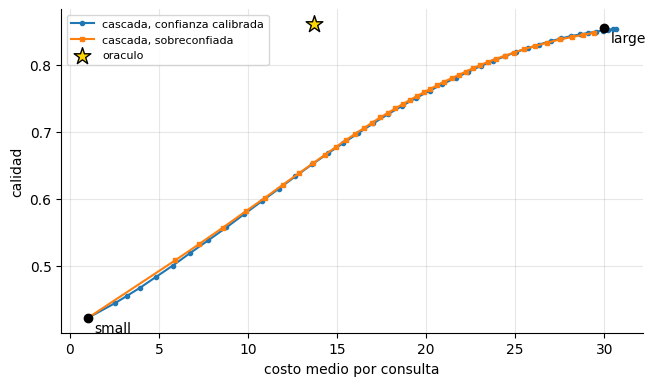

In [4]:
W2 = World(tiers=[t for t in DEFAULT_TIERS if t.name != "medium"]); D2 = W2.sample(100_000, np.random.default_rng(1)); W2o = World(tiers=W2.tiers, conf_kind="overconfident"); D2o = W2o.sample(100_000, np.random.default_rng(1))
lams = np.linspace(0, 1.0, 41)
def curva(w, d): return pd.DataFrame([{**PO.evaluate(PO.cascade(d, w, [l])), "lambda": l} for l in lams])
cal_c, over_c = curva(W2, D2), curva(W2o, D2o)
q_large = PO.evaluate(PO.always_tier(D2, W2, "large"))["quality"]
def ahorro_a_igual_calidad(c, objetivo):
    ok = c[c.quality >= objetivo]; return float(ok.mean_cost.min()) if len(ok) else np.nan
filas = []
for nom, c in (("calibrada", cal_c), ("sobreconfiada", over_c)):
    for frac in (0.90, 0.95, 0.98):
        objetivo = frac * q_large; costo = ahorro_a_igual_calidad(c, objetivo); filas.append({"confianza": nom, "calidad_objetivo": f"{frac:.0%} de la del grande ({objetivo:.3f})", "costo_minimo": costo, "ahorro_vs_grande_%": 100 * (1 - costo / 30) if costo == costo else np.nan})
av = pd.DataFrame(filas); print(av.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7.5, 4.2)); ax.plot(cal_c.mean_cost, cal_c.quality, "o-", ms=3, label="cascada, confianza calibrada"); ax.plot(over_c.mean_cost, over_c.quality, "s-", ms=3, label="cascada, sobreconfiada")
for t in W2.tiers: e = PO.evaluate(PO.always_tier(D2, W2, t.name)); ax.scatter(e["mean_cost"], e["quality"], c="k", zorder=5); ax.annotate(t.name, (e["mean_cost"], e["quality"]), textcoords="offset points", xytext=(5, -10))
o = PO.evaluate(PO.oracle_router(D2, W2)); ax.scatter(o["mean_cost"], o["quality"], marker="*", s=160, c="gold", edgecolor="k", zorder=6, label="oraculo"); ax.set_xlabel("costo medio por consulta"); ax.set_ylabel("calidad"); ax.legend(fontsize=8); plt.show()

In [5]:
# area bajo la curva de Pareto (calidad vs costo) y lo que la confianza "promete" frente a lo que entrega
def area(c): c = c.sort_values("mean_cost"); return float(np.trapezoid(c.quality, c.mean_cost) / (c.mean_cost.max() - c.mean_cost.min()))
prom = []
for nom, d in (("calibrada", D2), ("sobreconfiada", D2o)):
    for lam in (0.5, 0.7, 0.9):
        acep = d[d.conf_small >= lam]; prom.append({"confianza": nom, "umbral": lam, "aceptadas_%": 100 * len(acep) / len(d), "precision_declarada": acep.conf_small.mean(), "precision_real": acep.correct_small.mean(), "brecha": acep.conf_small.mean() - acep.correct_small.mean()})
pm = pd.DataFrame(prom); print(pm.round(3).to_string(index=False))
print(f"\nArea media bajo la curva calidad-costo: calibrada {area(cal_c):.4f}, sobreconfiada {area(over_c):.4f}")

    confianza  umbral  aceptadas_%  precision_declarada  precision_real  brecha
    calibrada  0.5000      38.5840               0.7180          0.7030  0.0150
    calibrada  0.7000      19.8270               0.8330          0.8080  0.0250
    calibrada  0.9000       4.8960               0.9560          0.8950  0.0610
sobreconfiada  0.5000      38.4080               0.8100          0.7100  0.1000
sobreconfiada  0.7000      27.9310               0.8890          0.7680  0.1210
sobreconfiada  0.9000      13.9950               0.9680          0.8360  0.1320

Area media bajo la curva calidad-costo: calibrada 0.6720, sobreconfiada 0.6662


In [6]:
av_i = av.set_index(["confianza", "calidad_objetivo"]); gap9 = pm.set_index(["confianza", "umbral"]).brecha
print("Lectura:")
print(f"  Hallazgo contraintuitivo: la FRONTERA costo-calidad de la cascada casi no cambia con la calibracion (area {area(cal_c):.4f} vs {area(over_c):.4f}; ahorro al 95% de calidad: {av_i.iloc[1]['ahorro_vs_grande_%']:.1f}% vs {av_i.iloc[4]['ahorro_vs_grande_%']:.1f}%). La sobreconfianza es una transformacion monotona de la senal y la cascada solo usa el ORDEN de las confianzas.")
print(f"  La calibracion importa cuando el umbral se fija leyendo la confianza como probabilidad: con umbral 0.9 la confianza calibrada declara {pm[(pm.confianza == 'calibrada') & (pm.umbral == 0.9)].precision_declarada.iloc[0]:.2f} y entrega {pm[(pm.confianza == 'calibrada') & (pm.umbral == 0.9)].precision_real.iloc[0]:.2f}; la sobreconfiada declara {pm[(pm.confianza == 'sobreconfiada') & (pm.umbral == 0.9)].precision_declarada.iloc[0]:.2f} y entrega {pm[(pm.confianza == 'sobreconfiada') & (pm.umbral == 0.9)].precision_real.iloc[0]:.2f} (brecha {gap9[('sobreconfiada', 0.9)]:.2f}).")
print(f"  Ahorro realista: para conservar el 95% de la calidad del grande, la cascada ahorra ≈{av_i.iloc[1]['ahorro_vs_grande_%']:.0f}% del costo (un modelo pequeno de 42% de acierto escala mucho); el oraculo ahorra {100 * (1 - o['mean_cost'] / 30):.0f}% a calidad {o['quality']:.3f}. La diferencia es el valor de una senal de confianza perfecta.")

Lectura:
  Hallazgo contraintuitivo: la FRONTERA costo-calidad de la cascada casi no cambia con la calibracion (area 0.6720 vs 0.6662; ahorro al 95% de calidad: 18.7% vs 18.6%). La sobreconfianza es una transformacion monotona de la senal y la cascada solo usa el ORDEN de las confianzas.
  La calibracion importa cuando el umbral se fija leyendo la confianza como probabilidad: con umbral 0.9 la confianza calibrada declara 0.96 y entrega 0.90; la sobreconfiada declara 0.97 y entrega 0.84 (brecha 0.13).
  Ahorro realista: para conservar el 95% de la calidad del grande, la cascada ahorra ≈19% del costo (un modelo pequeno de 42% de acierto escala mucho); el oraculo ahorra 54% a calidad 0.860. La diferencia es el valor de una senal de confianza perfecta.


## 4. Enrutador aprendido frente a cascada

Alternativa: **predecir antes de llamar** si el modelo pequeño acertará, usando atributos observables de la consulta (longitud, dominio…), y enviar a pequeño o grande **sin pagar la consulta fallida**. Se entrena una regresión logística con 20.000 consultas y se evalúa en otras 100.000; los atributos son versiones ruidosas de la dificultad (`feature_noise`). Se barre el umbral $\tau$ y se compara la frontera con la de la cascada, para atributos informativos (ruido 0,5), medios (1) y poco informativos (3).

In [7]:
from sklearn.metrics import roc_auc_score
filas = []; casc_by = {}
for ruido in (0.5, 1.0, 3.0):
    wr = World(tiers=W2.tiers, feature_noise=ruido); tr = wr.sample(20_000, np.random.default_rng(10)); te = wr.sample(100_000, np.random.default_rng(11)); casc_by[ruido] = pd.DataFrame([{**PO.evaluate(PO.cascade(te, wr, [l])), "lambda": l} for l in lams])
    m = PO.LogisticReg().fit(tr[PO.FEATS].values, tr.correct_small.values); ph = m.predict_proba(te[PO.FEATS].values); auc_f = roc_auc_score(te.correct_small, ph); auc_c = roc_auc_score(te.correct_small, te.conf_small)
    for tau in np.linspace(0.05, 0.95, 19): r_, _ = PO.learned_router(tr, te, wr, tau); filas.append({"ruido_atributos": ruido, "tau": tau, **PO.evaluate(r_), "AUC_atributos": auc_f, "AUC_confianza": auc_c})
rt = pd.DataFrame(filas)
def calidad_a_costo(cc, cq, costo): o = np.argsort(cc.values); return float(np.interp(costo, cc.values[o], cq.values[o]))
res = []
for ruido, g in rt.groupby("ruido_atributos"):
    for costo in (10.0, 15.0, 20.0):
        qr = calidad_a_costo(g.mean_cost, g.quality, costo); qc = calidad_a_costo(casc_by[ruido].mean_cost, casc_by[ruido].quality, costo)
        res.append({"ruido_atributos": ruido, "costo": costo, "calidad_enrutador": qr, "calidad_cascada": qc, "dif": qr - qc, "AUC_atributos": g.AUC_atributos.iloc[0], "AUC_confianza": g.AUC_confianza.iloc[0]})
rr = pd.DataFrame(res); rr.round(3)

,ruido_atributos,costo,calidad_enrutador,calidad_cascada,dif,AUC_atributos,AUC_confianza
0,0.5000,10.0000,0.5860,0.5810,0.0040,0.7890,0.8010
1,0.5000,15.0000,0.6810,0.6770,0.0040,0.7890,0.8010
2,0.5000,20.0000,0.7630,0.7580,0.0050,0.7890,0.8010
3,1.0000,10.0000,0.5820,0.5810,0.0000,0.7400,0.8010
4,1.0000,15.0000,0.6710,0.6770,-0.0060,0.7400,0.8010
5,1.0000,20.0000,0.7500,0.7580,-0.0080,0.7400,0.8010
6,3.0000,10.0000,0.5700,0.5810,-0.0110,0.6160,0.8010
7,3.0000,15.0000,0.6480,0.6770,-0.0280,0.6160,0.8010
8,3.0000,20.0000,0.7240,0.7580,-0.0340,0.6160,0.8010


In [8]:
xr = rr.set_index(["ruido_atributos", "costo"])
print("Lectura (calidad a igual costo medio):")
print(f"  AUC para predecir si el pequeno acierta: atributos {rr.groupby('ruido_atributos').AUC_atributos.first().round(3).to_dict()} vs confianza del propio modelo {rr.AUC_confianza.iloc[0]:.3f}.")
print(f"  Con atributos informativos (ruido 0.5), a costo 15 el enrutador logra {xr.loc[(0.5, 15.0), 'calidad_enrutador']:.3f} frente a {xr.loc[(0.5, 15.0), 'calidad_cascada']:.3f} de la cascada ({xr.loc[(0.5, 15.0), 'dif']:+.3f}); con atributos pobres (ruido 3), {xr.loc[(3.0, 15.0), 'calidad_enrutador']:.3f} vs {xr.loc[(3.0, 15.0), 'calidad_cascada']:.3f} ({xr.loc[(3.0, 15.0), 'dif']:+.3f}).")
print("  El enrutador evita pagar la llamada fallida, pero solo vale lo que valgan los atributos; la cascada usa la senal del propio modelo y no necesita entrenamiento.")

Lectura (calidad a igual costo medio):
  AUC para predecir si el pequeno acierta: atributos {0.5: 0.789, 1.0: 0.74, 3.0: 0.616} vs confianza del propio modelo 0.801.
  Con atributos informativos (ruido 0.5), a costo 15 el enrutador logra 0.681 frente a 0.677 de la cascada (+0.004); con atributos pobres (ruido 3), 0.648 vs 0.677 (-0.028).
  El enrutador evita pagar la llamada fallida, pero solo vale lo que valgan los atributos; la cascada usa la senal del propio modelo y no necesita entrenamiento.


## 5. Control conforme del riesgo: un umbral con garantía

La cascada hasta ahora fija el umbral «a ojo». **Control conforme del riesgo**: sea $L_i(\lambda)=\mathbf 1[\text{conf}_i\ge\lambda,\ \text{small falla},\ \text{large acierta}]$ la **pérdida de calidad** de aceptar la respuesta pequeña frente a usar siempre el grande (no creciente en $\lambda$). Con $n$ consultas de calibración se elige el menor $\hat\lambda$ tal que
$$\frac{n}{n+1}\,\hat R_n(\lambda)+\frac{1}{n+1}\le\varepsilon .$$
Si calibración y prueba son intercambiables, $\mathbb E[L_{\text{prueba}}(\hat\lambda)]\le\varepsilon$ **en muestra finita y sin supuestos sobre la calibración de la confianza**. Se valida por simulación (600 repeticiones independientes de calibración/prueba) y se contrasta con el umbral ingenuo (el menor con riesgo empírico $\le\varepsilon$, sin la corrección).

In [9]:
filas = []
for kind in ("calibrated", "overconfident"):
    wk = World(tiers=W2.tiers, conf_kind=kind)
    for eps in (0.01, 0.03):
        for n_cal in (50, 150, 500, 2000):
            for cons in (True, False):
                r = CF.validate_guarantee(wk, n_cal, 4000, eps, reps=400, seed=int(eps * 1000) + n_cal, conservative=cons); filas.append({"confianza": kind, "eps": eps, "n_calibracion": n_cal, "metodo": "conforme" if cons else "ingenuo", **r})
cfm = pd.DataFrame(filas); cfm.pivot_table(index=["confianza", "eps", "n_calibracion"], columns="metodo", values=["risk_mean", "violation_frac", "accept_mean"]).round(4)

accept_mean         risk_mean          \
metodo                                conforme ingenuo  conforme ingenuo   
confianza     eps    n_calibracion                                         
calibrated    0.0100 50                 0.0000  0.0965    0.0000  0.0156   
                     150                0.0473  0.0890    0.0057  0.0122   
                     500                0.0781  0.0897    0.0095  0.0114   
                     2000               0.0806  0.0837    0.0096  0.0101   
              0.0300 50                 0.1031  0.1799    0.0169  0.0347   
                     150                0.1534  0.1791    0.0257  0.0323   
                     500                0.1734  0.1808    0.0298  0.0317   
                     2000               0.1747  0.1767    0.0299  0.0304   
overconfident 0.0100 50                 0.0000  0.0930    0.0000  0.0160   
                     150                0.0292  0.0742    0.0042  0.0112   
                     500                0.0561  0.0737    0.0079  0.0105   
                     2000               0.0660  0.0710    0.0090  0.0097   
              0.0300 50                 0.0966  0.1796    0.0167  0.0349   
                     150                0.1509  0.1790    0.0259  0.0324   
                     500                0.1723  0.1804    0.0297  0.0317   
                     2000               0.1743  0.1764    0.0298  0.0303   

                                   violation_frac          
metodo                                   conforme ingenuo  
confianza     eps    n_calibracion                         
calibrated    0.0100 50                    0.0000  0.4825  
                     150                   0.1800  0.5275  
                     500                   0.3625  0.5450  
                     2000                  0.3725  0.4600  
              0.0300 50                    0.1925  0.5250  
                     150                   0.3175  0.4950  
                     500                   0.4500  0.5525  
                     2000                  0.4925  0.5175  
overconfident 0.0100 50                    0.0000  0.5225  
                     150                   0.1725  0.5275  
                     500                   0.3875  0.5275  
                     2000                  0.3575  0.4450  
              0.0300 50                    0.1900  0.5175  
                     150                   0.3225  0.5150  
                     500                   0.4500  0.5450  
                     2000                  0.4500  0.5100

In [10]:
cft = cfm.set_index(["confianza", "eps", "n_calibracion", "metodo"])
print("Lectura:")
cfc = cfm[cfm.metodo == "conforme"]
print(f"  Conforme: el riesgo medio de prueba NUNCA supera eps en ninguna de las {len(cfc)} configuraciones (maximo exceso {np.max(cfc.risk_mean - cfc.eps):+.4f}, error de Monte Carlo ~0.001); vale con confianza calibrada y sobreconfiada (la garantia no depende de la calibracion).")
print(f"  Ingenuo: con n=50 y eps=0.01 el riesgo medio es {cft.loc[('calibrated', 0.01, 50, 'ingenuo'), 'risk_mean']:.4f} (objetivo 0.01) y viola el objetivo en el {cft.loc[('calibrated', 0.01, 50, 'ingenuo'), 'violation_frac']:.0%} de las repeticiones; el conforme, {cft.loc[('calibrated', 0.01, 50, 'conforme'), 'risk_mean']:.4f}.")
print(f"  Con n=50 y eps=0.01 el conforme no acepta nada del modelo pequeno (riesgo 0.0000): la condicion n/(n+1)*R + 1/(n+1) <= eps exige n >= 1/eps - 1 = 99 consultas de calibracion; con menos, la unica opcion con garantia es escalar siempre.")
print(f"  Costo de la garantia: con pocos datos el conforme acepta menos al modelo pequeno (n=50: {cft.loc[('calibrated', 0.03, 50, 'conforme'), 'accept_mean']:.1%} vs {cft.loc[('calibrated', 0.03, 50, 'ingenuo'), 'accept_mean']:.1%} del ingenuo); con n=2000 la diferencia casi desaparece ({cft.loc[('calibrated', 0.03, 2000, 'conforme'), 'accept_mean']:.1%} vs {cft.loc[('calibrated', 0.03, 2000, 'ingenuo'), 'accept_mean']:.1%}).")

Lectura:
  Conforme: el riesgo medio de prueba NUNCA supera eps en ninguna de las 16 configuraciones (maximo exceso -0.0001, error de Monte Carlo ~0.001); vale con confianza calibrada y sobreconfiada (la garantia no depende de la calibracion).
  Ingenuo: con n=50 y eps=0.01 el riesgo medio es 0.0156 (objetivo 0.01) y viola el objetivo en el 48% de las repeticiones; el conforme, 0.0000.
  Con n=50 y eps=0.01 el conforme no acepta nada del modelo pequeno (riesgo 0.0000): la condicion n/(n+1)*R + 1/(n+1) <= eps exige n >= 1/eps - 1 = 99 consultas de calibracion; con menos, la unica opcion con garantia es escalar siempre.
  Costo de la garantia: con pocos datos el conforme acepta menos al modelo pequeno (n=50: 10.3% vs 18.0% del ingenuo); con n=2000 la diferencia casi desaparece (17.5% vs 17.7%).


## 6. Caché semántico: aciertos frente a respuestas equivocadas

Un caché semántico reutiliza una respuesta previa si el embedding de la consulta nueva es parecido (coseno $\ge\tau$). Ahorra llamadas, pero un acierto con **otra intención** es una respuesta equivocada. Se simula un flujo de 4.000 consultas con 40 intenciones (distribución Zipf) y ruido en los embeddings. Con un costo por llamada de 6 y un costo $K$ por respuesta equivocada, el costo neto por consulta es $(1-h)\cdot 6+w\cdot K$ ($h$ = tasa de aciertos, $w$ = fracción de consultas respondidas mal por el caché).

In [11]:
taus = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98]; filas = []
for ruido in (0.4, 0.8):
    for tau in taus:
        r = [simulate_cache(4000, 40, ruido, tau, np.random.default_rng(s)) for s in range(5)]; filas.append({"ruido": ruido, "tau": tau, **{k: float(np.mean([x[k] for x in r])) for k in r[0]}})
ch = pd.DataFrame(filas)
for K in (10, 30, 100): ch[f"costo_neto_K={K}"] = (1 - ch.hit_rate) * 6 + ch.wrong_answers * K
print(ch[ch.ruido == 0.8].round(3).to_string(index=False))
opt = {(ru, K): ch[ch.ruido == ru].set_index("tau")[f"costo_neto_K={K}"].idxmin() for ru in (0.4, 0.8) for K in (10, 30, 100)}; print("\nTau optimo por (ruido, K):", opt)

 ruido    tau  hit_rate  error_rate_on_hits  wrong_answers  calls_saved  costo_neto_K=10  costo_neto_K=30  costo_neto_K=100
0.8000 0.5000    0.9790              0.1370         0.1340       0.9790           1.4660           4.1450           13.5220
0.8000 0.6000    0.9520              0.1030         0.0980       0.9520           1.2680           3.2240           10.0700
0.8000 0.7000    0.8760              0.0630         0.0550       0.8760           1.2920           2.3890            6.2280
0.8000 0.8000    0.6630              0.0220         0.0150       0.6630           2.1700           2.4640            3.4930
0.8000 0.8500    0.4470              0.0100         0.0040       0.4470           3.3590           3.4460            3.7510
0.8000 0.9000    0.1700              0.0040         0.0010       0.1700           4.9890           5.0020            5.0470
0.8000 0.9500    0.0060              0.0000         0.0000       0.0060           5.9660           5.9660            5.9660
0.8000 0

In [12]:
g = ch[ch.ruido == 0.8].set_index("tau")
print("Lectura (ruido 0.8):")
print(f"  A tau=0.5 el cache acierta el {g.loc[0.5, 'hit_rate']:.0%} de las consultas pero el {g.loc[0.5, 'error_rate_on_hits']:.0%} de esos aciertos es una respuesta equivocada; a tau=0.9, {g.loc[0.9, 'hit_rate']:.0%} de aciertos y {g.loc[0.9, 'error_rate_on_hits']:.0%} de errores entre ellos; a tau=0.98, {g.loc[0.98, 'hit_rate']:.1%} de aciertos y {g.loc[0.98, 'error_rate_on_hits']:.1%} de errores.")
print(f"  El umbral optimo depende de cuanto cuesta equivocarse: con K=10, tau*={opt[(0.8, 10)]}; con K=100, tau*={opt[(0.8, 100)]}. Con ruido bajo (0.4) el optimo es {opt[(0.4, 10)]} para K=10 y {opt[(0.4, 100)]} para K=100: casi no hay errores y el umbral deja de importar.")
print(f"  El ahorro maximo de costo neto frente a no usar cache (6.0) es {6 - ch[ch.ruido == 0.8]['costo_neto_K=30'].min():.2f} por consulta con K=30.")

Lectura (ruido 0.8):
  A tau=0.5 el cache acierta el 98% de las consultas pero el 14% de esos aciertos es una respuesta equivocada; a tau=0.9, 17% de aciertos y 0% de errores entre ellos; a tau=0.98, 0.0% de aciertos y 0.0% de errores.
  El umbral optimo depende de cuanto cuesta equivocarse: con K=10, tau*=0.6; con K=100, tau*=0.8. Con ruido bajo (0.4) el optimo es 0.7 para K=10 y 0.7 para K=100: casi no hay errores y el umbral deja de importar.
  El ahorro maximo de costo neto frente a no usar cache (6.0) es 3.61 por consulta con K=30.


## 7. Enrutamiento en línea: bandidos

Sin datos de calibración previos, el sistema puede **aprender mientras opera**: cada consulta se envía a un nivel (brazo) y solo se observa la recompensa de ese nivel, $r=\text{acierto}-\lambda\cdot\text{costo}/\text{costo}_{\max}$. Se comparan $\varepsilon$-greedy ($\varepsilon=0{,}1$), UCB1, Thompson y la política **codiciosa** (sin exploración) por su *pseudo-arrepentimiento* acumulado frente al mejor brazo fijo, promediado en 20 semillas, con $\lambda=0{,}3$ (el mejor brazo es un nivel intermedio). Un algoritmo bueno tiene arrepentimiento **sublineal**: $R(2T)/R(T)<2$.

Mejor brazo para lambda=0.3: medium; recompensas esperadas por brazo: {'small': np.float64(0.412), 'medium': np.float64(0.596), 'large': np.float64(0.553)}


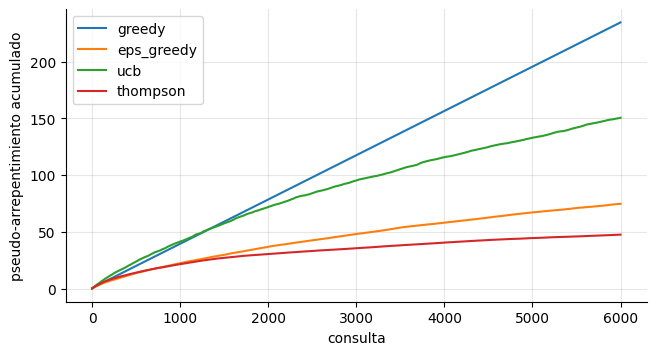

,arrepentimiento_T/2,arrepentimiento_T,razon R(T)/R(T/2)
greedy,117.5270,234.5080,1.9950
eps_greedy,48.0870,74.7360,1.5540
ucb,95.2460,150.5030,1.5800
thompson,35.5780,47.5510,1.3370


In [13]:
LAM = 0.3; T = 6000; algos = ["greedy", "eps_greedy", "ucb", "thompson"]; reg = {}
for a in algos: reg[a] = np.mean([BA.run_bandit(W, T, LAM, a, np.random.default_rng(s))["regret"] for s in range(20)], axis=0)
info = BA.run_bandit(W, T, LAM, "ucb", np.random.default_rng(0)); print(f"Mejor brazo para lambda={LAM}: {info['best_arm']}; recompensas esperadas por brazo: {dict(zip([t.name for t in W.tiers], np.round(info['mu'], 3)))}")
tb = pd.DataFrame({a: {"arrepentimiento_T/2": reg[a][T // 2 - 1], "arrepentimiento_T": reg[a][-1], "razon R(T)/R(T/2)": reg[a][-1] / reg[a][T // 2 - 1]} for a in algos}).T
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for a in algos: ax.plot(reg[a], label=a)
ax.set_xlabel("consulta"); ax.set_ylabel("pseudo-arrepentimiento acumulado"); ax.legend(); plt.show(); tb.round(3)

In [14]:
print("Lectura:")
print(f"  Razon R(T)/R(T/2) (lineal = 2.0): " + ", ".join(f"{a} {tb.loc[a, 'razon R(T)/R(T/2)']:.2f}" for a in algos) + ".")
ult = {a: (reg[a][-1] - reg[a][2 * T // 3]) / (T - 2 * T // 3) for a in algos}
print(f"  UCB y Thompson son sublineales ({tb.loc['ucb', 'razon R(T)/R(T/2)']:.2f} y {tb.loc['thompson', 'razon R(T)/R(T/2)']:.2f}). Arrepentimiento por consulta en el ultimo tercio (debe tender a 0 si es sublineal): " + ", ".join(f"{a} {ult[a]:.4f}" for a in algos) + ". Epsilon-greedy explora al azar el 10% del tiempo para siempre y mantiene una tasa constante.")
print(f"  La politica codiciosa tiene arrepentimiento final medio {tb.loc['greedy', 'arrepentimiento_T']:.1f} (frente a {tb.loc['thompson', 'arrepentimiento_T']:.1f} de Thompson), con una cola mala: a veces se queda con un brazo subóptimo para siempre.")

Lectura:
  Razon R(T)/R(T/2) (lineal = 2.0): greedy 2.00, eps_greedy 1.55, ucb 1.58, thompson 1.34.
  UCB y Thompson son sublineales (1.58 y 1.34). Arrepentimiento por consulta en el ultimo tercio (debe tender a 0 si es sublineal): greedy 0.0390, eps_greedy 0.0083, ucb 0.0173, thompson 0.0035. Epsilon-greedy explora al azar el 10% del tiempo para siempre y mantiene una tasa constante.
  La politica codiciosa tiene arrepentimiento final medio 234.5 (frente a 47.6 de Thompson), con una cola mala: a veces se queda con un brazo subóptimo para siempre.


## 8. Asignación bajo presupuesto

Con probabilidades predichas de acierto por nivel para cada consulta, ¿cómo repartir un **presupuesto de costo** total para maximizar los aciertos esperados? El problema es una mochila con elección múltiple. La **relajación de Lagrange** asigna a cada consulta el nivel que maximiza $p_{ik}-\lambda c_k$ y busca el $\lambda$ que agota el presupuesto; el remanente se gasta en las mejoras de mayor ganancia por costo. Su valor se acota con la **relajación lineal** (programación lineal, `linprog`). Se compara, a igual costo medio, con la cascada y con un reparto aleatorio. Las probabilidades se predicen con una regresión logística por nivel, entrenada con 20.000 consultas.

In [15]:
wa = World(feature_noise=0.5); tr = wa.sample(20_000, np.random.default_rng(20)); te = wa.sample(4000, np.random.default_rng(21)); costos = np.array([t.cost_per_call for t in wa.tiers]); nombres = [t.name for t in wa.tiers]
modelos = {n: PO.LogisticReg().fit(tr[PO.FEATS].values, tr[f"correct_{n}"].values) for n in nombres}
Pp = np.column_stack([modelos[n].predict_proba(te[PO.FEATS].values) for n in nombres]); Y = np.column_stack([te[f"correct_{n}"].values for n in nombres])
Pp = np.maximum.accumulate(Pp, axis=1)                                      # la asignacion usa probabilidades no decrecientes con el nivel
filas = []
for B_medio in (4.0, 8.0, 12.0, 16.0, 20.0, 25.0):
    B = B_medio * len(te); a = OP.allocate(Pp, costos, B); real = Y[np.arange(len(te)), a].mean(); esp = OP.value(Pp, a) / len(te)
    # cascada de 3 niveles con umbrales iguales, calibrada por biseccion para gastar lo mismo
    lo, hi = 0.0, 1.0
    for _ in range(30):
        mid = (lo + hi) / 2; c_ = PO.evaluate(PO.cascade(te, wa, [mid, mid]))["mean_cost"]; (lo, hi) = (mid, hi) if c_ < B_medio else (lo, mid)
    rc = PO.cascade(te, wa, [hi, hi]); azar_q = []
    rg = np.random.default_rng(0)
    for _ in range(30):
        x = rg.choice(3, len(te), p=None); 
        while costos[x].mean() > B_medio: x[rg.integers(0, len(te))] = 0
        azar_q.append(Y[np.arange(len(te)), x].mean())
    filas.append({"costo_medio_permitido": B_medio, "calidad_asignacion": real, "calidad_esperada": esp, "calidad_cascada": PO.evaluate(rc)["quality"], "costo_cascada": PO.evaluate(rc)["mean_cost"], "calidad_azar_factible": np.mean(azar_q), "costo_real_asignacion": costos[a].mean()})
asg = pd.DataFrame(filas).set_index("costo_medio_permitido"); print(asg.round(4).to_string())
# cota LP en una submuestra (300 consultas)
sub = np.arange(300); ub = [(OP.value(Pp[sub], OP.allocate(Pp[sub], costos, b * 300)), OP.lp_upper_bound(Pp[sub], costos, b * 300)) for b in (4.0, 8.0, 12.0, 20.0)]
print("\nValor entero vs cota LP (300 consultas):", [(round(v, 3), round(u, 3), round(u - v, 3)) for v, u in ub])

                       calidad_asignacion  calidad_esperada  calidad_cascada  costo_cascada  calidad_azar_factible  costo_real_asignacion
costo_medio_permitido                                                                                                                    
4.0000                             0.5938            0.5901           0.4862         4.0015                 0.4779                 4.0000
8.0000                             0.6872            0.6822           0.5680         8.0005                 0.5574                 8.0000
12.0000                            0.7325            0.7342           0.6442        12.0010                 0.6366                11.9998
16.0000                            0.7735            0.7787           0.7108        16.0045                 0.6424                15.9995
20.0000                            0.8035            0.8131           0.7632        20.0020                 0.6424                19.9992
25.0000                           

In [16]:
print("Lectura:")
print(f"  Con costo medio 12 (40% del costo del grande), la asignacion alcanza {asg.loc[12.0, 'calidad_asignacion']:.3f} de calidad real frente a {asg.loc[12.0, 'calidad_cascada']:.3f} de la cascada (a costo {asg.loc[12.0, 'costo_cascada']:.1f}) y {asg.loc[12.0, 'calidad_azar_factible']:.3f} de un reparto aleatorio factible; la calidad esperada segun las probabilidades predichas fue {asg.loc[12.0, 'calidad_esperada']:.3f}.")
print(f"  La asignacion gasta el presupuesto ({asg.loc[12.0, 'costo_real_asignacion']:.2f} <= 12) y su valor esta a {max(u - v for v, u in ub):.2f} aciertos esperados (de 300 consultas) de la cota de la relajacion lineal: no hay una solucion entera mucho mejor.")
print("  La ventaja de la asignacion sobre la cascada es que decide con la informacion de TODAS las consultas a la vez (reparte el presupuesto donde rinde mas) y no paga llamadas descartadas.")

Lectura:
  Con costo medio 12 (40% del costo del grande), la asignacion alcanza 0.733 de calidad real frente a 0.644 de la cascada (a costo 12.0) y 0.637 de un reparto aleatorio factible; la calidad esperada segun las probabilidades predichas fue 0.734.
  La asignacion gasta el presupuesto (12.00 <= 12) y su valor esta a 0.03 aciertos esperados (de 300 consultas) de la cota de la relajacion lineal: no hay una solucion entera mucho mejor.
  La ventaja de la asignacion sobre la cascada es que decide con la informacion de TODAS las consultas a la vez (reparte el presupuesto donde rinde mas) y no paga llamadas descartadas.


## 9. Pruebas automáticas

In [17]:
# 9.1 referencias: niveles ordenados y el oraculo domina consulta por consulta
assert ref.loc["small", "quality"] < ref.loc["medium", "quality"] < ref.loc["large", "quality"] and ref.loc["oraculo", "quality"] >= ref.loc["large", "quality"] and ref.loc["oraculo", "mean_cost"] < 0.35 * 30
# 9.2 confianza: calibrada acierta lo que dice; sobreconfiada no
assert abs(cc.acierto_real.iloc[-1] - cc.confianza_media.iloc[-1]) < 0.06 and co.confianza_media.iloc[-1] - co.acierto_real.iloc[-1] > 0.08
# 9.3 la frontera de la cascada casi no depende de la calibracion; el umbral leido como probabilidad si
assert abs(area(cal_c) - area(over_c)) < 0.02 and pm.set_index(["confianza", "umbral"]).brecha[("sobreconfiada", 0.9)] > pm.set_index(["confianza", "umbral"]).brecha[("calibrada", 0.9)] + 0.04
assert cal_c.sort_values("mean_cost").quality.is_monotonic_increasing or (np.diff(cal_c.sort_values("mean_cost").quality) > -0.01).all()
# 9.4 ahorro de la cascada: positivo y menor que el del oraculo
assert 5 < av_i.iloc[1]["ahorro_vs_grande_%"] < 100 * (1 - o["mean_cost"] / 30)
# 9.5 enrutador: con atributos pobres pierde frente a la cascada; AUC de atributos decrece con el ruido
assert rr.groupby("ruido_atributos").AUC_atributos.first().is_monotonic_decreasing and xr.loc[(3.0, 15.0), "dif"] < -0.01
# 9.6 conforme: garantia en esperanza en todas las configuraciones; el ingenuo viola con pocos datos
assert (cfc.risk_mean <= cfc.eps + 0.002).all() and cft.loc[("calibrated", 0.01, 50, "ingenuo"), "risk_mean"] > 0.01 and cft.loc[("calibrated", 0.01, 50, "ingenuo"), "violation_frac"] > 0.3
assert cft.loc[("calibrated", 0.03, 50, "conforme"), "accept_mean"] < cft.loc[("calibrated", 0.03, 50, "ingenuo"), "accept_mean"] and abs(cft.loc[("calibrated", 0.03, 2000, "conforme"), "accept_mean"] - cft.loc[("calibrated", 0.03, 2000, "ingenuo"), "accept_mean"]) < 0.03
# 9.7 cache: aciertos decrecen con tau, errores entre aciertos tambien, y existe un tau interior optimo
gg = ch[ch.ruido == 0.8].set_index("tau"); assert gg.hit_rate.is_monotonic_decreasing and gg.error_rate_on_hits.iloc[0] > gg.error_rate_on_hits.iloc[5] and 0.5 < opt[(0.8, 100)] < 0.98 and opt[(0.8, 10)] <= opt[(0.8, 100)]
assert gg["costo_neto_K=30"].min() < 6.0 - 1.0
# 9.8 bandidos: UCB y Thompson sublineales; el codicioso sin exploracion es peor; epsilon-greedy mantiene una tasa constante
assert tb.loc["ucb", "razon R(T)/R(T/2)"] < 1.8 and tb.loc["thompson", "razon R(T)/R(T/2)"] < 1.6 and tb.loc["greedy", "arrepentimiento_T"] > 2 * tb.loc["thompson", "arrepentimiento_T"] and ult["eps_greedy"] > 2 * ult["thompson"]
# 9.9 asignacion: respeta el presupuesto, supera al reparto aleatorio y esta cerca de la cota LP
assert (asg.costo_real_asignacion <= asg.index.values + 1e-9).all() and (asg.calidad_asignacion > asg.calidad_azar_factible).all() and max(u - v for v, u in ub) < 1.0 and (np.diff(asg.calidad_asignacion) > -0.01).all()
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Potencial | El oráculo logra la mejor calidad a ~26 % del costo del grande: ese es el techo del enrutamiento | Medir cuánto de ese potencial captura cada política |
| Cascada | Con un modelo pequeño débil, conservar el 95 % de la calidad del grande ahorra ~19 % del costo | No esperar ahorros enormes si el nivel barato acierta poco |
| Calibración | La frontera de la cascada solo depende del orden de la confianza; la calibración importa al leer el umbral como probabilidad (se esperaba 90 %, se obtuvo 84 %) | No fijar umbrales a ojo: calibrar con datos |
| Enrutador aprendido | Iguala a la cascada con atributos informativos y pierde con atributos pobres | Combinarlo con la señal de confianza |
| Control conforme | Garantiza en muestra finita una pérdida de calidad ≤ ε sin supuestos sobre la calibración; exige n ≥ 1/ε − 1 consultas de calibración; el umbral ingenuo viola el objetivo con pocos datos | Calibrar el umbral con la corrección de muestra finita |
| Caché semántico | El umbral óptimo depende del costo de una respuesta equivocada | Elegir τ minimizando el costo neto con la penalización real |
| Bandidos | UCB y Thompson tienen arrepentimiento sublineal; ε-greedy mantiene una tasa constante; sin exploración se atasca | Thompson o UCB para aprender en línea |
| Asignación | Reparte el presupuesto mejor que la cascada y un reparto aleatorio, y queda cerca de la cota de la relajación lineal | Resolver la asignación con optimización cuando se tienen probabilidades predichas |

**Límites que no deben ocultarse**

- Todo es simulado: las habilidades, costos y señales de confianza son supuestos; los modelos reales tienen perfiles por tema y confianza menos limpia.
- El control conforme supone intercambiabilidad entre calibración y producción; con deriva de la distribución la garantía se pierde.
- La cascada solo considera dos o tres niveles y una confianza escalar; no modela latencia como restricción ni límites de tasa.
- El caché usa embeddings sintéticos con ruido gaussiano; los reales tienen estructura de clústeres más compleja.
- Los bandidos no usan contexto; un bandido contextual aprendería a enrutar según atributos de la consulta.